
# Succession Benchmarks: Exploratory Data Analysis

## Niagara Succession Signal — Week 5

### Objective
Explore Canadian and Ontario business succession evidence to understand succession intentions, planning practices, expected business transfers, and barriers.

The analysis will distinguish Ontario-wide and Canada-wide evidence from Niagara-specific findings and document the limitations of using aggregate data.

In [1]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the project root
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "data").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

print("Project root:", PROJECT_ROOT)
print("Interim directory exists:", INTERIM_DIR.exists())
print("Processed directory exists:", PROCESSED_DIR.exists())


Project root: C:\GitRepo\niagara-succession-signal
Interim directory exists: True
Processed directory exists: True


In [2]:
# Locate and load the four cleaned Ontario succession datasets

from pathlib import Path
import pandas as pd

dataset_files = {
    "intentions": "statcan_33101196_ontario_cleaned.csv",
    "expectations": "statcan_33101197_ontario_cleaned.csv",
    "importance_factors": "statcan_33101198_ontario_cleaned.csv",
    "scenarios_likelihood": "statcan_33101199_ontario_cleaned.csv",
}

datasets = {}

for name, filename in dataset_files.items():
    file_path = INTERIM_DIR / filename

    if file_path.exists():
        datasets[name] = pd.read_csv(file_path)
        print(f"{name}: {datasets[name].shape[0]:,} rows × {datasets[name].shape[1]} columns")
    else:
        print(f"NOT FOUND: {file_path}")

intentions: 476 rows × 15 columns
expectations: 476 rows × 15 columns
importance_factors: 1,360 rows × 16 columns
scenarios_likelihood: 1,020 rows × 16 columns


## Ontario succession benchmarks: initial exploratory analysis

### Data scope
- Source: four cleaned Statistics Canada succession tables.
- Geography: Ontario (not Niagara-specific).
- Reference year: 2026.
- Unit: percentages.
- These are aggregate survey estimates, not predictions for individual businesses.

### Initial observations
- 18.9% reported an intention to sell or transfer ownership within 10 years.
- 52.7% expected qualified buyers to be available; 26.5% expected a fair market price.
- 58.1% considered finding a buyer in Canada very important.
- 51.8% considered protecting employees very important.
- 26.4% considered scaling down or closing operations very likely if a suitable buyer or successor could not be found.

### Data-quality cautions
- Preserve Statistics Canada's status codes alongside estimates.
- Do not interpret missing or suppressed values as zero.
- Do not add timeline estimates to the overall intention estimate without confirming their denominators.
- Status codes A, B and C have not yet been interpreted in this analysis; consult the source metadata before drawing conclusions about estimate quality.



INTENTIONS ? ALL INDUSTRIES

,Intentions for businesses to sell or transfer ownership within the next 10 years,VALUE,STATUS
0,"Yes, business intends to sell or transfer owne...",18.9,A
1,"Yes, business intends to sell or transfer owne...",33.7,B
2,"Yes, business intends to sell or transfer owne...",27.5,B
3,"Yes, business intends to sell or transfer owne...",18.4,B
4,"Yes, business intends to sell or transfer owne...",20.4,B
5,"No, business does not intend to sell or transf...",43.0,A
6,Intentions for businesses to sell or transfer ...,38.1,A



EXPECTATIONS ? ALL INDUSTRIES


,Expectations related to selling or transferring of the business,VALUE,STATUS
0,There are likely to be qualified buyers for th...,52.7,C
1,A fair market price would be received for the ...,26.5,C
2,There is sufficient time and resources to purs...,17.4,C
3,"Professional or advisory support, such as a br...",25.4,C
4,Government programs or supports for facilitati...,1.5,A
5,Expectations related to selling or transferrin...,39.1,C
6,Expectations related to selling or transferrin...,1.9,A



IMPORTANCE ? ALL INDUSTRIES


,Considerations related to the sale or transfer of the business,Level of importance,VALUE,STATUS
0,Finding a buyer in Canada,Very important,58.1,C
1,Finding a buyer in Canada,Somewhat important,6.4,B
2,Finding a buyer in Canada,Not important,31.4,C
3,Finding a buyer in Canada,"Level of importance, unknown",4.1,A
4,Protecting employees,Very important,51.8,C
5,Protecting employees,Somewhat important,12.4,B
6,Protecting employees,Not important,31.0,C
7,Protecting employees,"Level of importance, unknown",4.8,B
8,Maintaining presence in the local community,Very important,49.9,C
9,Maintaining presence in the local community,Somewhat important,16.0,C



SCENARIOS ? ALL INDUSTRIES


,Various scenarios if business is unable to find a suitable buyer or successor,Likelihood,VALUE,STATUS
0,Continue operating under current ownership,Very likely,31.2,C
1,Continue operating under current ownership,Somewhat likely,21.8,C
2,Continue operating under current ownership,Somewhat unlikely,7.9,B
3,Continue operating under current ownership,Very unlikely,19.4,C
4,Continue operating under current ownership,"Likelihood, unknown",19.8,C
5,Sell at a reduced value or under less favorabl...,Very likely,15.2,B
6,Sell at a reduced value or under less favorabl...,Somewhat likely,25.4,C
7,Sell at a reduced value or under less favorabl...,Somewhat unlikely,11.9,C
8,Sell at a reduced value or under less favorabl...,Very unlikely,26.5,C
9,Sell at a reduced value or under less favorabl...,"Likelihood, unknown",21.0,C


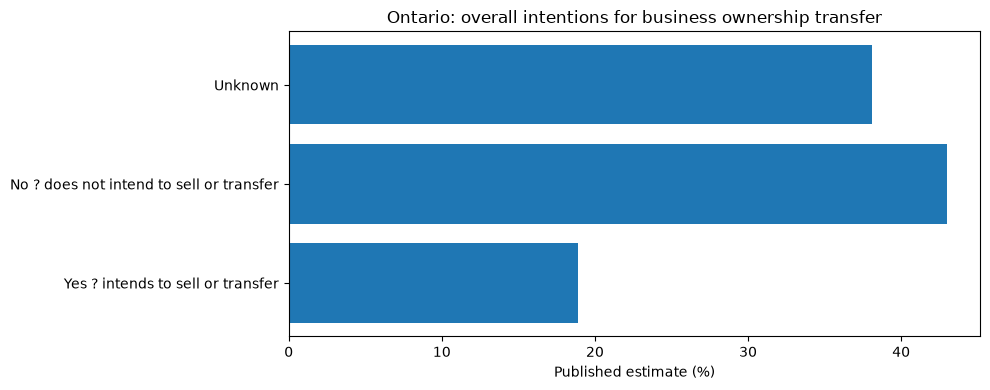

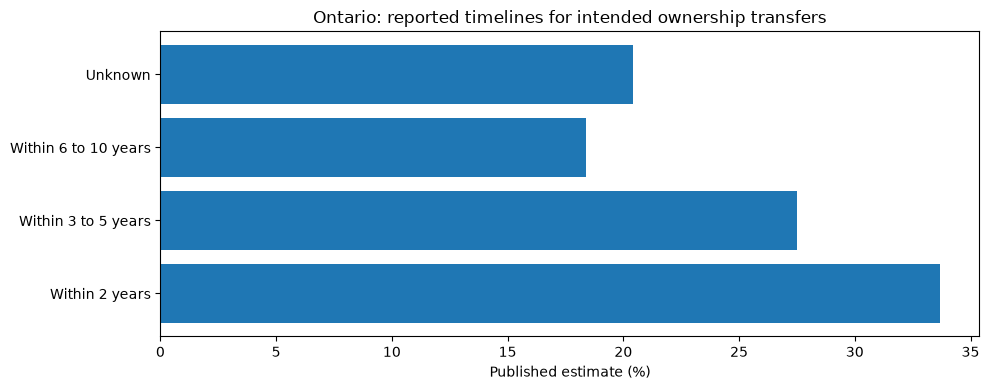

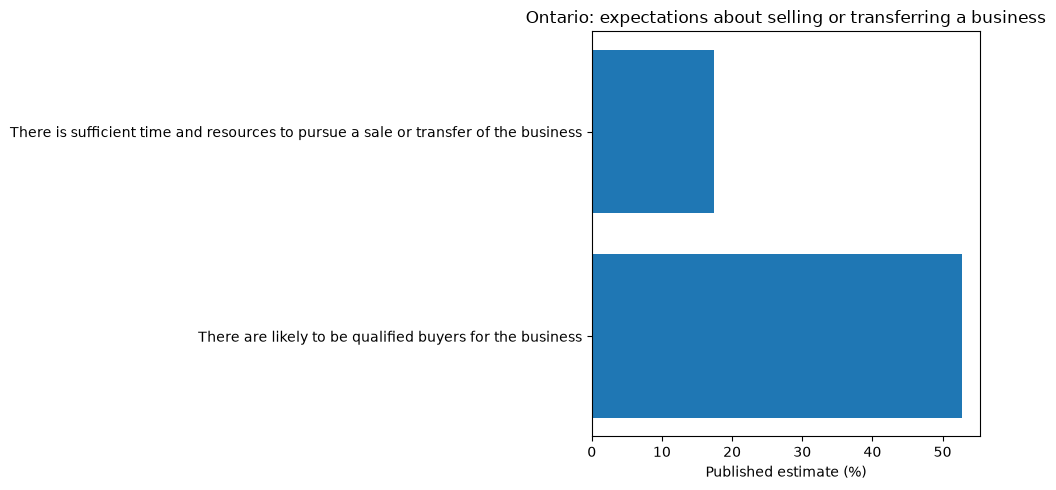

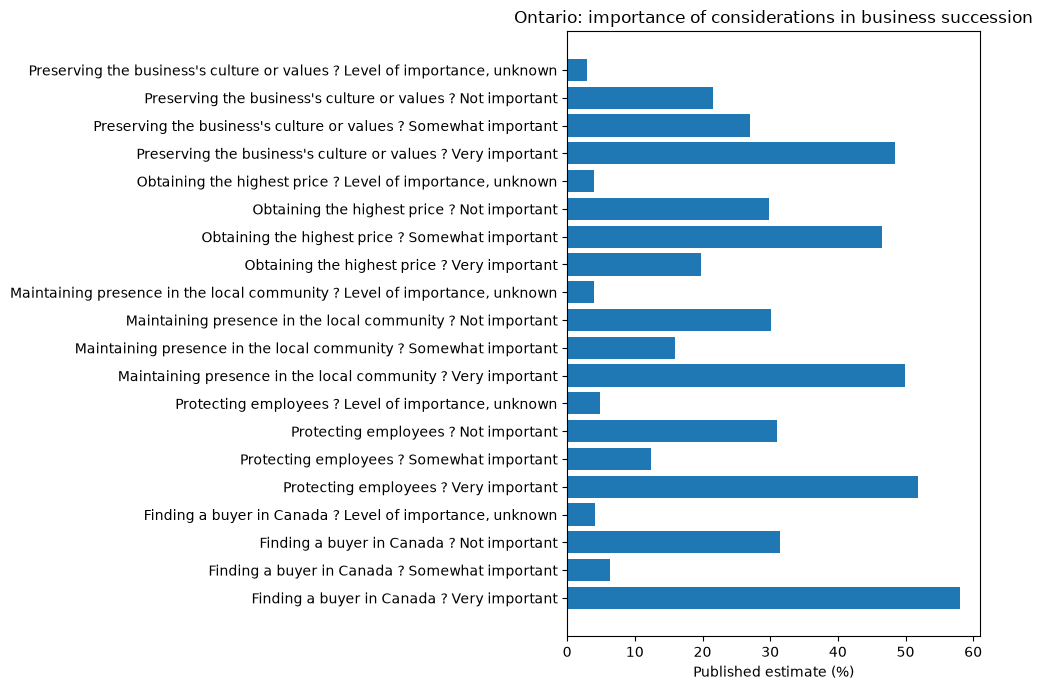

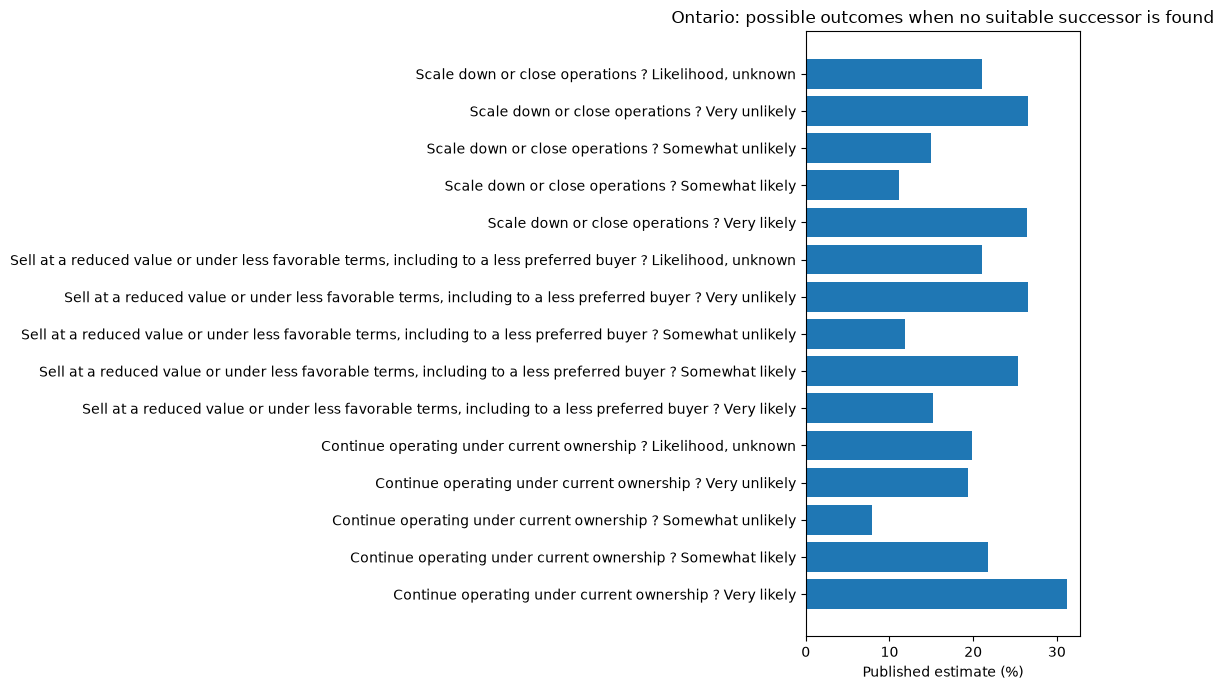

In [3]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "data" / "interim").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "data" / "interim").exists():
    raise FileNotFoundError("Could not locate the repository data/interim directory.")

data_dir = PROJECT_ROOT / "data" / "interim"

datasets = {
    "Intentions": "statcan_33101196_ontario_cleaned.csv",
    "Expectations": "statcan_33101197_ontario_cleaned.csv",
    "Importance": "statcan_33101198_ontario_cleaned.csv",
    "Scenarios": "statcan_33101199_ontario_cleaned.csv",
}

overall_label = (
    "North American Industry Classification System (NAICS), all industries"
)

def get_measure_column(df):
    excluded = {
        "REF_DATE", "GEO", "DGUID", "Business characteristics",
        "UOM", "UOM_ID", "SCALAR_FACTOR", "SCALAR_ID", "VECTOR",
        "COORDINATE", "VALUE", "STATUS", "TERMINATED", "DECIMALS",
        "Level of importance", "Likelihood"
    }
    return next(col for col in df.columns if col not in excluded)

loaded = {}
for name, filename in datasets.items():
    df = pd.read_csv(data_dir / filename)
    measure_col = get_measure_column(df)
    overall = df[
        df["Business characteristics"] == overall_label
    ].copy()
    loaded[name] = (overall, measure_col)

# Display the benchmark estimates and their original status codes.
for name, (df, measure_col) in loaded.items():
    print(f"\n{name.upper()} ? ALL INDUSTRIES")
    columns = [measure_col]
    for col in ["Level of importance", "Likelihood", "VALUE", "STATUS"]:
        if col in df.columns:
            columns.append(col)
    display(df[columns].reset_index(drop=True))

# Chart 1A: overall intentions (Yes / No / Unknown)
intentions, intention_col = loaded["Intentions"]
labels = intentions[intention_col].astype("string")

overall_mask = (
    (
        labels.str.startswith(
            "Yes, business intends to sell or transfer ownership",
            na=False
        )
        & ~labels.str.contains(", timeline", na=False)
    )
    | labels.str.startswith(
        "No, business does not intend to sell or transfer ownership",
        na=False
    )
    | labels.str.startswith(
        "Intentions for businesses to sell or transfer ownership",
        na=False
    )
)

overall_chart = intentions[overall_mask].copy()

def overall_intention_label(value):
    if value.startswith("Yes,"):
        return "Yes ? intends to sell or transfer"
    if value.startswith("No,"):
        return "No ? does not intend to sell or transfer"
    return "Unknown"

overall_chart["Label"] = overall_chart[intention_col].map(
    overall_intention_label
)

plt.figure(figsize=(10, 4))
plt.barh(overall_chart["Label"], overall_chart["VALUE"])
plt.xlabel("Published estimate (%)")
plt.title("Ontario: overall intentions for business ownership transfer")
plt.tight_layout()
plt.show()

# Chart 1B: reported timelines (keep separate from overall intentions)
timeline_chart = intentions[
    labels.str.contains(", timeline ", na=False)
].copy()

timeline_chart["Label"] = (
    timeline_chart[intention_col]
    .str.split(", timeline ", n=1)
    .str[-1]
    .str.capitalize()
)

plt.figure(figsize=(10, 4))
plt.barh(timeline_chart["Label"], timeline_chart["VALUE"])
plt.xlabel("Published estimate (%)")
plt.title("Ontario: reported timelines for intended ownership transfers")
plt.tight_layout()
plt.show()

# Interpret timeline estimates separately; confirm their denominator
# in the source metadata before making conditional interpretations.

# Chart 2: expectations related to sale or transfer.
expectations, expectations_col = loaded["Expectations"]
expectations_chart = expectations[
    expectations[expectations_col].str.startswith(
        "There ", na=False
    )
]
plt.figure(figsize=(10, 5))
plt.barh(expectations_chart[expectations_col], expectations_chart["VALUE"])
plt.xlabel("Published estimate (%)")
plt.title("Ontario: expectations about selling or transferring a business")
plt.tight_layout()
plt.show()

# Chart 3: considerations, grouped by importance level.
importance, importance_col = loaded["Importance"]
importance_chart = importance.dropna(subset=["VALUE"]).copy()
importance_chart["Label"] = (
    importance_chart[importance_col] + " ? " +
    importance_chart["Level of importance"]
)
plt.figure(figsize=(10, 7))
plt.barh(importance_chart["Label"], importance_chart["VALUE"])
plt.xlabel("Published estimate (%)")
plt.title("Ontario: importance of considerations in business succession")
plt.tight_layout()
plt.show()

# Chart 4: possible scenarios if no suitable buyer or successor is found.
scenarios, scenarios_col = loaded["Scenarios"]
scenarios_chart = scenarios.dropna(subset=["VALUE"]).copy()
scenarios_chart["Label"] = (
    scenarios_chart[scenarios_col] + " ? " +
    scenarios_chart["Likelihood"]
)
plt.figure(figsize=(11, 7))
plt.barh(scenarios_chart["Label"], scenarios_chart["VALUE"])
plt.xlabel("Published estimate (%)")
plt.title("Ontario: possible outcomes when no suitable successor is found")
plt.tight_layout()
plt.show()


Source: CFIB Succession Tsunami, 2022; Canada-wide survey
Population recorded in source: 2479 small-business owners


,category,value,unit,geography,source_year
5,Formal written plan,9,percent,Canada,2022
6,Informal unwritten plan,45,percent,Canada,2022
7,No succession plan,46,percent,Canada,2022


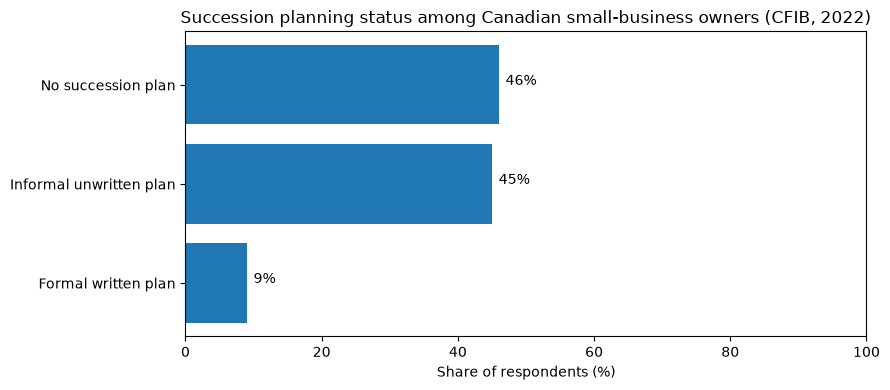

In [4]:
# Step 4: CFIB succession planning status (Canada, 2022)
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
while not (project_root / "data" / "processed" / "cfib" / "cfib_succession_evidence_structured.csv").exists():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not locate the project root and CFIB CSV.")
    project_root = project_root.parent
cfib_path = (
    project_root / "data" / "processed" / "cfib"
    / "cfib_succession_evidence_structured.csv"
)
cfib = pd.read_csv(cfib_path)

planning = cfib[
    (cfib["topic"] == "Succession planning")
    & (cfib["measure"] == "Current succession planning status")
].copy()

planning["value"] = pd.to_numeric(planning["value"], errors="coerce")
planning = planning.dropna(subset=["value"])

print("Source: CFIB Succession Tsunami, 2022; Canada-wide survey")
print("Population recorded in source:", planning["population"].iloc[0])
display(planning[["category", "value", "unit", "geography", "source_year"]])

plt.figure(figsize=(9, 4))
plt.barh(planning["category"], planning["value"])
plt.xlabel("Share of respondents (%)")
plt.title("Succession planning status among Canadian small-business owners (CFIB, 2022)")
plt.xlim(0, 100)
for y, value in enumerate(planning["value"]):
    plt.text(value + 1, y, f"{value:.0f}%")
plt.tight_layout()
plt.show()


Source: Statistics Canada table; Ontario-wide estimates, 2026
Measure: Intends to sell or transfer ownership within the next 10 years
Industry estimates with available numeric values: 16
Industry estimates omitted because VALUE was missing/suppressed: 0
Status codes are retained for transparency; consult the source metadata for their definitions.


,Business characteristics,VALUE,STATUS,UOM
56,Information and cultural industries [51],5.8,A,Percent
91,Health care and social assistance [62],9.6,B,Percent
77,"Professional, scientific and technical service...",11.6,B,Percent
63,Finance and insurance [52],12.2,C,Percent
49,Transportation and warehousing [48-49],13.4,B,Percent
21,Construction [23],15.5,B,Percent
84,"Administrative and support, waste management a...",16.4,C,Percent
98,"Arts, entertainment and recreation [71]",19.1,D,Percent
28,Manufacturing [31-33],19.6,D,Percent
7,"Agriculture, forestry, fishing and hunting [11]",22.5,C,Percent


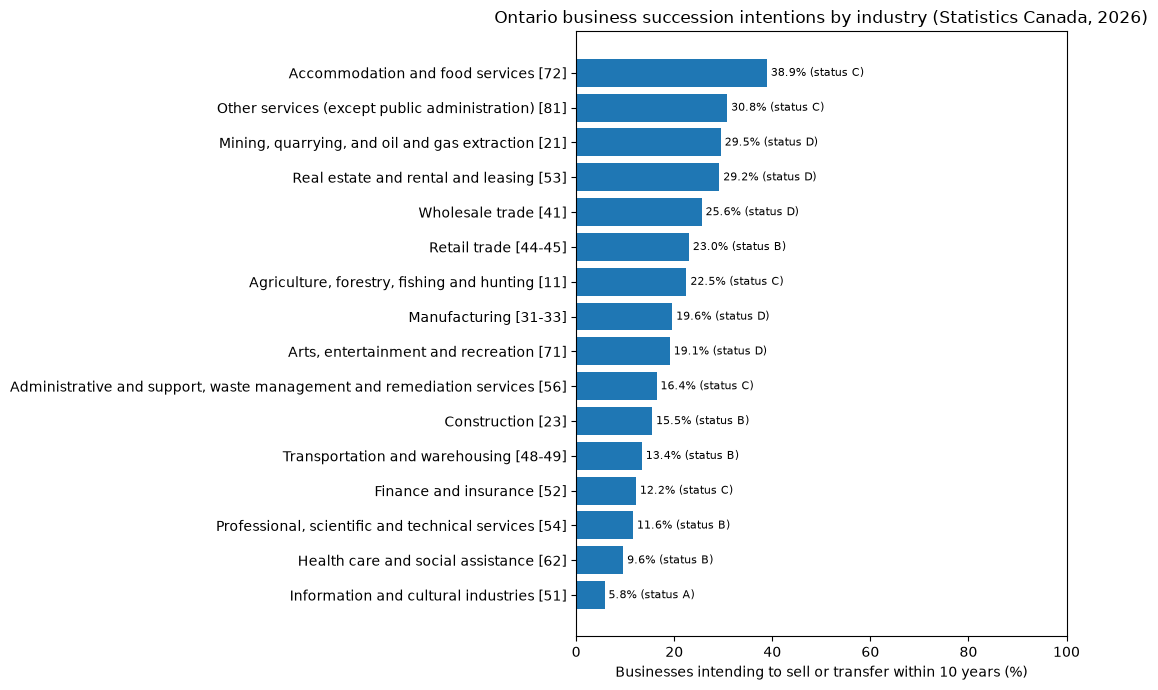

In [5]:
# Step 6: Ontario industry comparison of intended sale or transfer
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
while not (project_root / "data" / "interim" / "statcan_33101196_ontario_cleaned.csv").exists():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not locate the project root and Ontario intentions CSV.")
    project_root = project_root.parent

data_path = project_root / "data" / "interim" / "statcan_33101196_ontario_cleaned.csv"
df = pd.read_csv(data_path)

measure_col = "Intentions for businesses to sell or transfer ownership within the next 10 years"
overall_yes = "Yes, business intends to sell or transfer ownership within the next 10 years"

industry = df[
    df["Business characteristics"].str.contains(r"\[\d{2}(?:-\d{2})?\]$", na=False)
    & (df[measure_col].str.strip() == overall_yes)
].copy()

industry["VALUE"] = pd.to_numeric(industry["VALUE"], errors="coerce")
industry = industry.dropna(subset=["VALUE"]).sort_values("VALUE")

print("Source: Statistics Canada table; Ontario-wide estimates, 2026")
print("Measure: Intends to sell or transfer ownership within the next 10 years")
print("Industry estimates with available numeric values:", len(industry))
print("Industry estimates omitted because VALUE was missing/suppressed:", 16 - len(industry))
print("Status codes are retained for transparency; consult the source metadata for their definitions.")
display(industry[["Business characteristics", "VALUE", "STATUS", "UOM"]])

plt.figure(figsize=(11, 7))
bars = plt.barh(industry["Business characteristics"], industry["VALUE"])
plt.xlabel("Businesses intending to sell or transfer within 10 years (%)")
plt.title("Ontario business succession intentions by industry (Statistics Canada, 2026)")
plt.xlim(0, 100)

for bar, (_, row) in zip(bars, industry.iterrows()):
    label = f'{row["VALUE"]:.1f}% (status {row["STATUS"]})'
    plt.text(row["VALUE"] + 0.8, bar.get_y() + bar.get_height() / 2, label, va="center", fontsize=8)

plt.tight_layout()
plt.show()
